# Week 1: Canadian Parliamentary Voting Preprocessing

**DTU Data Mining 02807**  
**Research question:** How does party alignment vary across policy topics in the Canadian Parliament over time, as shown by patterns of voting agreement and party dissent?

This notebook documents collection, integration, quality assessment, exploratory analysis and preparation of House of Commons voting data. It does not perform graph clustering or Apriori analysis yet.


## Sources and collection strategy

The study covers Parliaments 41–45 (approximately 2011–present). Official House participant XML is the primary source for `PersonId`, MP identity, dated party, vote position, paired status, constituency, province and date. Official vote-detail HTML is used for subject, full motion text and bill metadata. The sources are joined using `parliament-session-division` (`vote_id`). Raw XML and HTML remain under `data/raw`; cleaned outputs are written separately.

A 30-vote validation sample found identical participant member sets and agreement for names, parties, vote choices, paired indicators, constituencies and provinces. This supports complementary use, but does not establish perfect consistency for every historical division.

```text
Official House sources → XML participants + HTML vote metadata
                     → integration → cleaning → exploration
                     → analysis-ready datasets → Week 2 networks/dissent mining
```


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from canadian_parliament.config import (
    PROJECT_ROOT,
    PROCESSED_DATA_DIR,
    PROCESSED_CLEAN_DATA_DIR,
)

ROOT = PROJECT_ROOT
PROCESSED = PROCESSED_DATA_DIR
CLEAN = PROCESSED_CLEAN_DATA_DIR
CLEAN.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')


## Dataset overview

Files are discovered rather than assumed. The tables below report observations, variables, missing cells and exact duplicate rows.

In [2]:
expected = ['canada_parliament_votes.csv', 'votes_metadata.csv', 'members_metadata.csv', 'voting_matrix.csv', 'party_dissent.csv', 'apriori_transactions.csv', 'data_quality_report.csv']
tables, overview = {}, []
for name in expected:
    path = PROCESSED / name
    if path.exists():
        df = pd.read_csv(path, low_memory=False)
        tables[name] = df
        overview.append({'file': name, 'observations': len(df), 'variables': len(df.columns), 'missing_cells': int(df.isna().sum().sum()), 'duplicates': int(df.duplicated().sum()), 'columns': ', '.join(df.columns)})
display(pd.DataFrame(overview))
for name, df in tables.items():
    print(f'\n{name}: {df.dtypes.astype(str).to_dict()}')
    display(df.head(2))
print('Raw XML files:', len(list((ROOT/'data'/'raw').glob('vote_*.xml'))))
print('Raw HTML files:', len(list((ROOT/'data'/'raw'/'vote_pages').glob('*.html'))))


,file,observations,variables,missing_cells,duplicates,columns
0,canada_parliament_votes.csv,981918,6,981918,0,"member_id, vote_id, vote, party, date, topic"
1,votes_metadata.csv,3423,18,27825,0,"vote_id, parliament, session, date, result, so..."
2,members_metadata.csv,247831,8,247831,0,"member_id, full_name, constituency, province, ..."
3,voting_matrix.csv,826,3424,1852551,0,"member_id, 41-1-1, 41-1-10, 41-1-100, 41-1-101..."
4,party_dissent.csv,974847,8,626,0,"member_id, vote_id, party, individual_vote, pa..."
5,apriori_transactions.csv,782,4,0,0,"transaction_id, vote_id, party, dissenting_mem..."
6,data_quality_report.csv,65,2,0,0,"metric, value"



canada_parliament_votes.csv: {'member_id': 'int64', 'vote_id': 'str', 'vote': 'str', 'party': 'str', 'date': 'str', 'topic': 'float64'}


,member_id,vote_id,vote,party,date,topic
0,71688,41-1-1,No,Conservative,2011-06-08,NaN
1,71824,41-1-1,No,Conservative,2011-06-08,NaN



votes_metadata.csv: {'vote_id': 'str', 'parliament': 'int64', 'session': 'int64', 'date': 'str', 'result': 'str', 'source_url': 'str', 'subject': 'str', 'motion_text': 'str', 'bill_number': 'str', 'bill_title': 'str', 'document_type': 'str', 'metadata_source': 'str', 'metadata_fetch_error': 'str', 'original_division_id': 'float64', 'motion_description': 'str', 'vote_question': 'str', 'topic': 'float64', 'topic_source': 'str'}


,vote_id,parliament,session,date,result,source_url,subject,motion_text,bill_number,bill_title,document_type,metadata_source,metadata_fetch_error,original_division_id,motion_description,vote_question,topic,topic_source
0,41-1-2,41,1,2011-06-13,Negatived,https://www.ourcommons.ca/Members/en/votes/41/1/2,Budgetary policy (amendment),That the motion be amended by deleting all the...,NaN,NaN,NaN,official vote detail page,NaN,NaN,NaN,NaN,NaN,NaN
1,41-1-1,41,1,2011-06-08,Negatived,https://www.ourcommons.ca/Members/en/votes/41/1/1,Budgetary policy (subamendment),That the amendment be amended by adding after ...,NaN,NaN,NaN,official vote detail page,NaN,NaN,NaN,NaN,NaN,NaN



members_metadata.csv: {'member_id': 'int64', 'full_name': 'str', 'constituency': 'str', 'province': 'str', 'party': 'str', 'party_start_date': 'str', 'party_end_date': 'float64', 'parliamentary_session': 'str'}


... (9 outputs left out)

Raw XML files:

 4065


Raw HTML files:

 3295


## Exploratory analysis

A long-table row is one recorded MP-vote observation. Parliament and session are extracted from `vote_id`. Recorded Yes, No, Paired and other outcomes remain distinct.

MP-vote observations: 981,918; unique MPs: 826; divisions: 3,423; parties: 12


,parliament,observations,divisions,mps
0,41,329190,1227,322
1,42,227477,870,349
2,43,66065,211,339
3,44,296291,928,348
4,45,62895,187,348


,date,observations
0,2011,29060
1,2012,133216
2,2013,54495
3,2014,70995
4,2015,43694
5,2016,53191
6,2017,73020
7,2018,98996
8,2019,2562
9,2020,16454


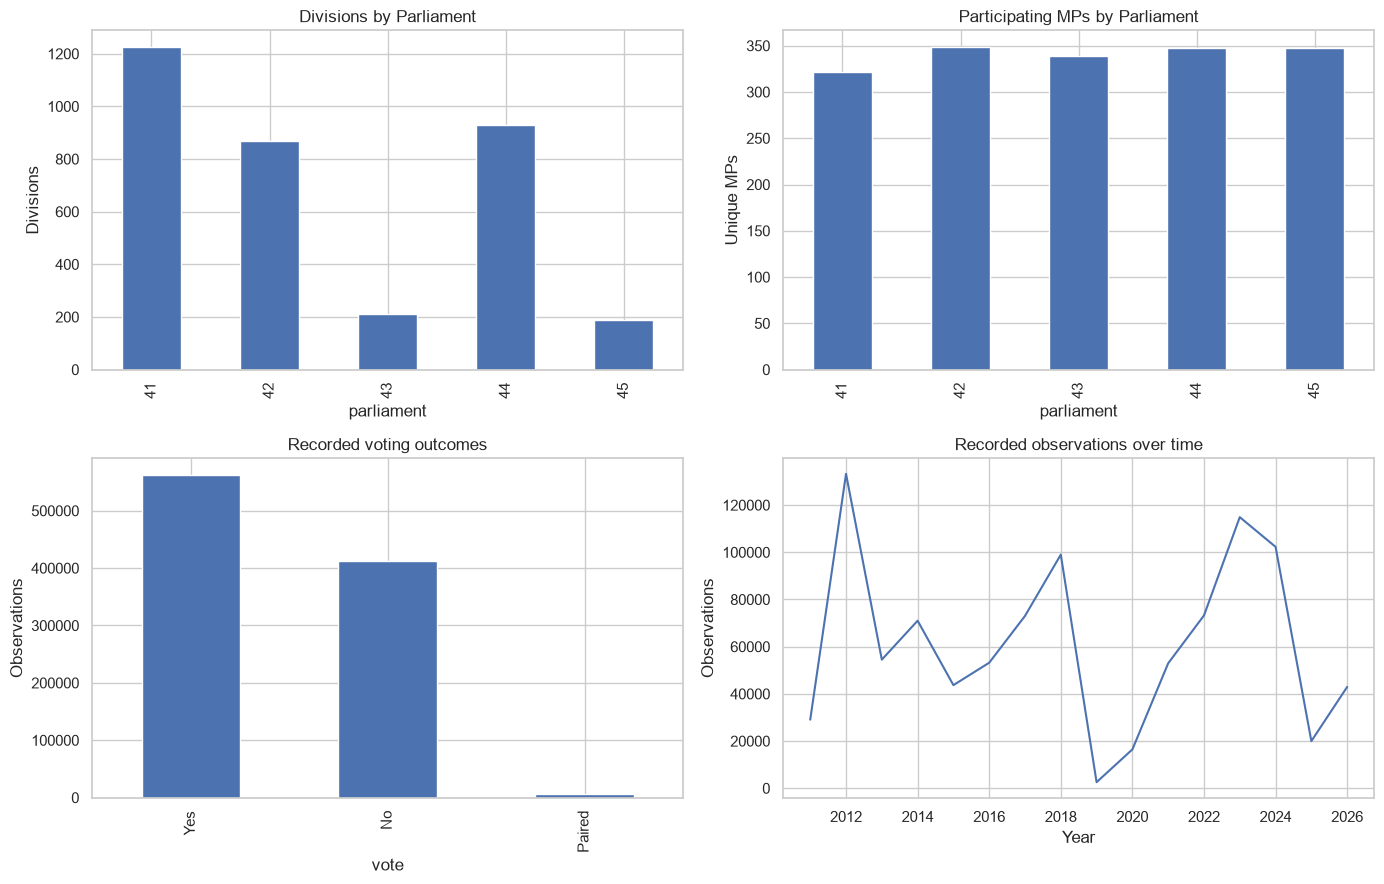

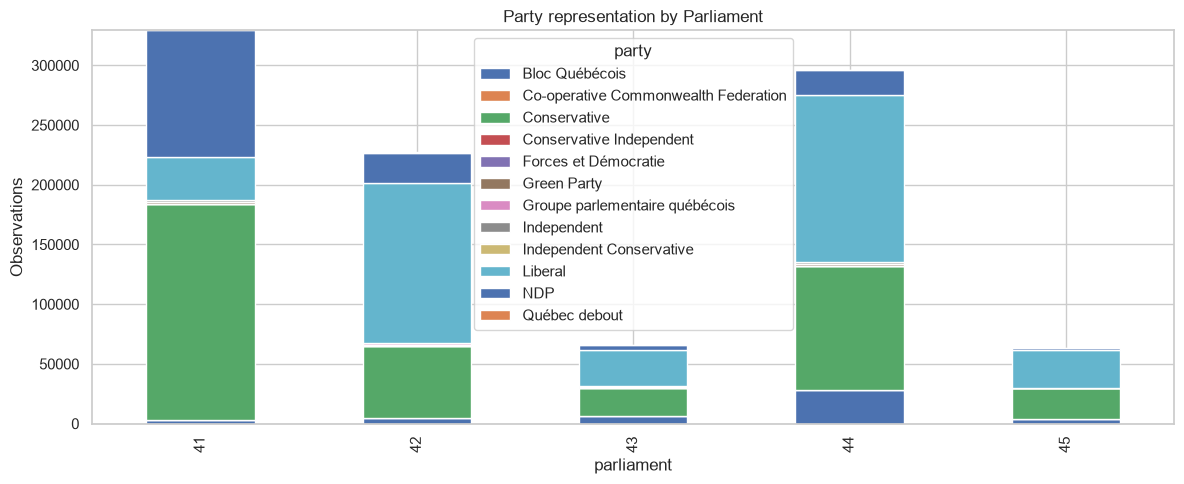

In [3]:
votes = tables['canada_parliament_votes.csv'].copy()
metadata = tables['votes_metadata.csv'].copy()
for df in (votes, metadata):
    df[['parliament','session','division']] = df['vote_id'].str.extract(r'^(\d+)-(\d+)-(\d+)$').astype('Int64')
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
print(f'MP-vote observations: {len(votes):,}; unique MPs: {votes.member_id.nunique():,}; divisions: {votes.vote_id.nunique():,}; parties: {votes.party.nunique():,}')
display(votes.groupby('parliament').agg(observations=('vote_id','size'), divisions=('vote_id','nunique'), mps=('member_id','nunique')).reset_index())
display(votes.groupby(votes.date.dt.year).size().rename('observations').reset_index(name='observations').tail(20))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
votes.groupby('parliament').vote_id.nunique().plot.bar(ax=axes[0,0], title='Divisions by Parliament', ylabel='Divisions')
votes.groupby('parliament').member_id.nunique().plot.bar(ax=axes[0,1], title='Participating MPs by Parliament', ylabel='Unique MPs')
votes.vote.value_counts().plot.bar(ax=axes[1,0], title='Recorded voting outcomes', ylabel='Observations')
votes.groupby(votes.date.dt.year).size().plot(ax=axes[1,1], title='Recorded observations over time', ylabel='Observations', xlabel='Year')
plt.tight_layout(); plt.show()
votes.groupby(['parliament','party']).size().unstack(fill_value=0).plot.bar(stacked=True, figsize=(12,5), title='Party representation by Parliament', ylabel='Observations'); plt.tight_layout(); plt.show()


## Missingness, matrix sparsity and quality

A missing matrix cell means no substantive Yes/No value is available for that MP-division pair. It is not a No vote. Paired, abstained and other non-substantive positions remain in the long table but are excluded from the numeric substantive matrix.

Matrix shape: 826 MPs x 3,423 divisions; observed: 974,847; missing: 1,852,551; density: 34.48%


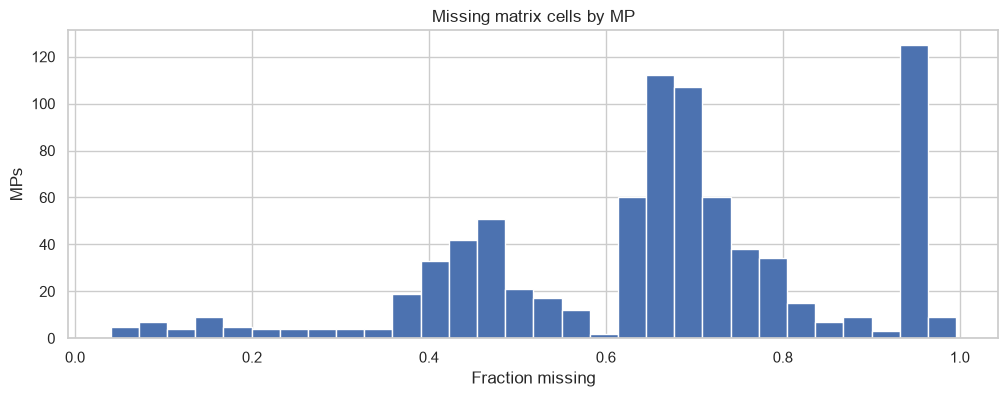

,check,count,percent_of_vote_records
0,missing_member_id,0,0.0
1,missing_vote_id,0,0.0
2,missing_date,0,0.0
3,missing_party,0,0.0
4,duplicate_member_vote,0,0.0
5,duplicate_vote_metadata,0,0.0
6,votes_without_metadata,0,0.0
7,members_without_member_metadata,0,0.0


Classified divisions: 0 / 3,423
No official topic classifications are currently available; no topic bar chart is drawn.


In [4]:
matrix = tables['voting_matrix.csv'].set_index('member_id')
observed = int(matrix.notna().sum().sum()); total = matrix.size
print(f'Matrix shape: {matrix.shape[0]:,} MPs x {matrix.shape[1]:,} divisions; observed: {observed:,}; missing: {total-observed:,}; density: {observed/total:.2%}')
plt.figure(figsize=(12,4)); plt.hist(matrix.isna().mean(axis=1), bins=30); plt.title('Missing matrix cells by MP'); plt.xlabel('Fraction missing'); plt.ylabel('MPs'); plt.show()
checks = {'missing_member_id': votes.member_id.isna().sum(), 'missing_vote_id': votes.vote_id.isna().sum(), 'missing_date': votes.date.isna().sum(), 'missing_party': votes.party.isna().sum(), 'duplicate_member_vote': votes.duplicated(['member_id','vote_id']).sum(), 'duplicate_vote_metadata': metadata.duplicated(['vote_id']).sum(), 'votes_without_metadata': (~votes.vote_id.isin(metadata.vote_id)).sum(), 'members_without_member_metadata': (~votes.member_id.isin(tables['members_metadata.csv'].member_id)).sum()}
display(pd.DataFrame([{'check': k, 'count': int(v), 'percent_of_vote_records': int(v)/len(votes)*100} for k,v in checks.items()]))
topic = metadata.assign(topic=metadata.topic.astype('string').fillna('').replace('', 'Unclassified'))
print(f"Classified divisions: {topic.loc[topic.topic.ne('Unclassified'),'vote_id'].nunique():,} / {metadata.vote_id.nunique():,}")
classified_topics = topic[topic.topic.ne('Unclassified')].topic.value_counts()
if classified_topics.empty:
    print('No official topic classifications are currently available; no topic bar chart is drawn.')
else:
    classified_topics.plot.barh(figsize=(9,5), title='Divisions by assigned topic', xlabel='Divisions'); plt.tight_layout(); plt.show()


## Preliminary party dissent

An MP dissents when their substantive Yes/No vote differs from the most common substantive vote among their recorded party on that division. Ties have no majority. This is disagreement with the observed party majority, not proof of a party whip or motivation.

Substantive observations: 974,847; dissenting: 3,246 (0.33%)


,count,sum,mean
party,,,
Independent,4722,419,0.088734
Conservative,392841,1362,0.003467
Liberal,368276,1216,0.003302
NDP,157481,198,0.001257
Green Party,4293,5,0.001165
Bloc Québécois,44927,45,0.001002
Groupe parlementaire québécois,1128,1,0.000887
Co-operative Commonwealth Federation,89,0,0.000000
Conservative Independent,126,0,0.000000


,tied_party_majority_decisions
0,626


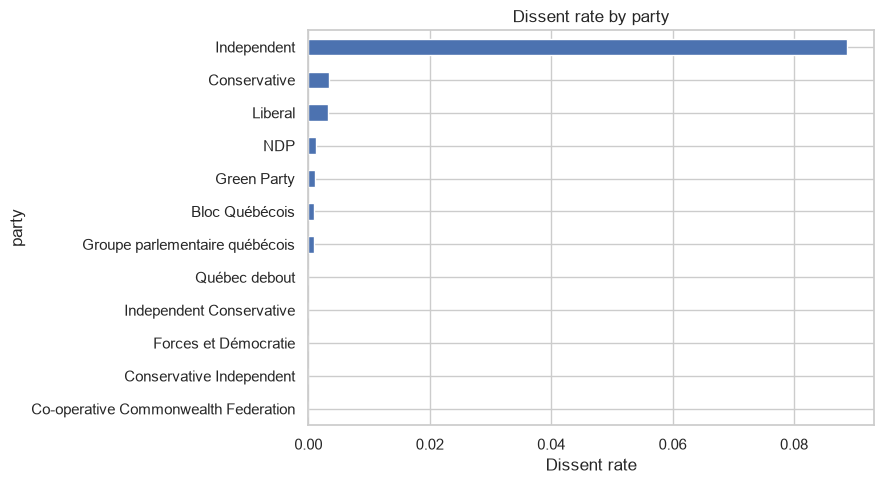

In [5]:
dissent = tables['party_dissent.csv'].copy(); substantive = dissent[dissent.individual_vote.isin(['Yes','No'])]
print(f'Substantive observations: {len(substantive):,}; dissenting: {int(substantive.dissent.sum()):,} ({substantive.dissent.mean():.2%})')
display(substantive.groupby('party').dissent.agg(['count','sum','mean']).sort_values('mean', ascending=False))
display(pd.DataFrame({'tied_party_majority_decisions': [int(dissent.majority_tied.fillna(False).sum())]}))
substantive.groupby('party').dissent.mean().sort_values().plot.barh(figsize=(9,5), title='Dissent rate by party', xlabel='Dissent rate'); plt.tight_layout(); plt.show()


## Cleaned analysis-ready exports

Raw files are not overwritten. Cleaned exports preserve non-substantive long-table outcomes, retain missing matrix cells, standardize dates and IDs, and retain subject, motion text, bill information and topic. Parliament-specific substantive matrices are also written for later agreement analysis.

In [6]:
clean_votes = votes[['member_id','vote_id','vote','party','date','topic','parliament','session','division']].copy(); clean_votes['member_id'] = clean_votes.member_id.astype('string'); clean_votes['vote_id'] = clean_votes.vote_id.astype('string'); clean_votes['date'] = clean_votes.date.dt.strftime('%Y-%m-%d'); clean_votes = clean_votes.drop_duplicates(['member_id','vote_id'])
clean_metadata = metadata.drop_duplicates('vote_id').copy(); clean_members = tables['members_metadata.csv'].drop_duplicates().copy(); clean_dissent = dissent.drop_duplicates(['member_id','vote_id']).copy()
clean_votes.to_csv(CLEAN/'votes_clean.csv', index=False); clean_metadata.to_csv(CLEAN/'votes_metadata_clean.csv', index=False); clean_members.to_csv(CLEAN/'members_metadata_clean.csv', index=False); clean_dissent.to_csv(CLEAN/'party_dissent_clean.csv', index=False); matrix.to_csv(CLEAN/'voting_matrix_clean.csv')
for parliament in sorted(clean_votes.parliament.dropna().unique()):
    ids = clean_votes.loc[clean_votes.parliament.eq(parliament) & clean_votes.vote.isin(['Yes','No']), 'vote_id'].unique(); matrix.loc[:, matrix.columns.intersection(ids)].to_csv(CLEAN/f'voting_matrix_{int(parliament)}_clean.csv')
print(f'Wrote cleaned datasets to {CLEAN.resolve()}')


Wrote cleaned datasets to data\processed_clean


## Limitations and Week 2 preparation

Parliamentary voting records provide direct empirical evidence of MPs' voting behaviour and form the foundation of this project. By examining how frequently MPs vote together or differently, we can measure political agreement and disagreement across parties, policy topics and parliamentary periods.

Some limitations must be considered. MPs serve for different periods and do not participate in every division. Therefore, pairwise agreement will use only jointly observed substantive Yes/No votes, retaining the number of shared votes. Party dissent is measured relative to the observed majority within each party and does not necessarily reveal MPs' motivations.

Incomplete topic metadata will be addressed using NLP techniques to classify parliamentary votes by policy area.

The cleaned data provides the foundation for Week 2: calculating pairwise voting agreement, constructing co-voting networks, visualizing voting relationships and applying Louvain or spectral community detection. Party dissent and transaction datasets will support subsequent dissent analysis and Apriori mining.